# Lab 13-05 · Plane Waves in Lossless and Lossy Media

Companion to [chapter 13-05](../../chapters/13-05-plane-waves.md). Four parts: snapshots of plane waves in lossless and lossy media; polarization traced over a cycle; the exact propagation constant of seawater against its two approximations; and the exact current distribution and AC resistance of a round copper wire. Run the cells in order.

In [1]:
import cmath, math
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq
from scipy.special import jv
eps0, mu0 = 8.8541878128e-12, 4e-7 * math.pi
eta0, sig_cu = math.sqrt(mu0 / eps0), 5.8e7

def gamma_eta(f, sigma, er=1.0):
    w = 2 * math.pi * f
    y, z = sigma + 1j * w * er * eps0, 1j * w * mu0
    g = cmath.sqrt(z * y)
    return (g if g.real >= 0 else -g), cmath.sqrt(z / y)

## Part 1 · Snapshots of E and H

At one instant, plot $E_x(z)$ and $\eta_0H_y(z)$ for a lossless wave and for a lossy one with $\alpha = \beta/5$.

**Predict first:** in the lossy medium, is $H$ ahead of or behind $E$ along $z$?

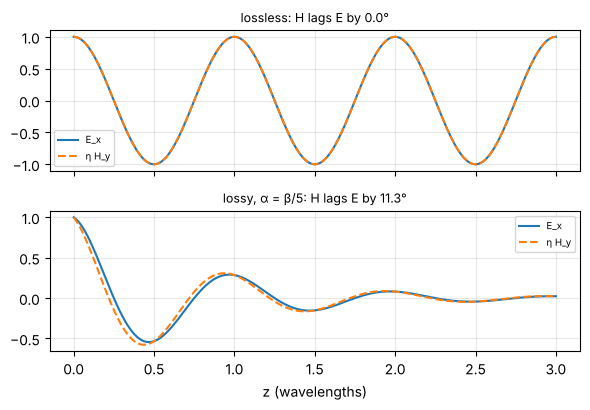

In [2]:
z = np.linspace(0, 3, 600)                       # in wavelengths
beta = 2 * math.pi
fig, axes = plt.subplots(2, 1, figsize=(6, 4.2), sharex=True)
for ax, alpha, label in ((axes[0], 0.0, 'lossless'), (axes[1], beta / 5, 'lossy, α = β/5')):
    g = alpha + 1j * beta
    eta_ratio = 1j * beta / g   # eta_c / eta = (j w mu / gamma) / (j w mu / j beta)
    E = (np.exp(-g * z)).real
    H = (np.exp(-g * z) / eta_ratio).real
    ax.plot(z, E, label='E_x'); ax.plot(z, H, '--', label='η H_y')
    ax.set_title(f"{label}: H lags E by {math.degrees(cmath.phase(eta_ratio)):.1f}°", fontsize=9); ax.grid(alpha=0.3); ax.legend(fontsize=7)
axes[-1].set_xlabel('z (wavelengths)'); plt.tight_layout(); plt.show()

## Part 2 · Polarization

Trace the tip of $\vec{E}(t)$ at $z$ = 0 for several phasors (wave travelling in $+z$). The sign of $(\vec{E}\times d\vec{E}/dt)_z$ gives the hand: positive is right-hand for $+z$ travel.

**Predict first:** which of these is right-hand: $\hat{x} - j\hat{y}$ or $\hat{x} + j\hat{y}$? What is the axial ratio of $\hat{x} + 2j\hat{y}$?

x + y   : linear, axial ratio inf
x - jy  : right-hand, axial ratio 1.000
x + jy  : left-hand, axial ratio 1.000
x + 2jy : left-hand, axial ratio 2.000


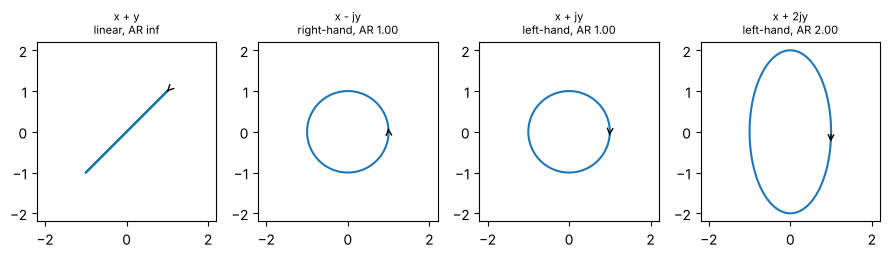

In [3]:
cases = {'x + y': (1, 1), 'x - jy': (1, -1j), 'x + jy': (1, 1j), 'x + 2jy': (1, 2j)}
wt = np.linspace(0, 2 * math.pi, 400, endpoint=False)
fig, axes = plt.subplots(1, 4, figsize=(9, 2.6))
for ax, (name, (Ex, Ey)) in zip(axes, cases.items()):
    ex, ey = (Ex * np.exp(1j * wt)).real, (Ey * np.exp(1j * wt)).real
    rot = np.mean(ex * np.gradient(ey) - ey * np.gradient(ex))
    sv = np.linalg.svd(np.stack([ex, ey]), compute_uv=False)
    ar = sv[0] / sv[1] if sv[1] > 1e-9 else float('inf')
    hand = 'linear' if abs(rot) < 1e-9 else ('right-hand' if rot > 0 else 'left-hand')
    ax.plot(ex, ey); ax.annotate('', (ex[10], ey[10]), (ex[0], ey[0]), arrowprops=dict(arrowstyle='->'))
    ax.set_aspect('equal'); ax.set_title(f"{name}\n{hand}, AR {ar:.2f}", fontsize=8); ax.set_xlim(-2.2, 2.2); ax.set_ylim(-2.2, 2.2)
    print(f"{name:8s}: {hand}, axial ratio {ar:.3f}")
plt.tight_layout(); plt.show()

## Part 3 · Seawater: exact against approximate

Compute α for seawater (σ = 4 S/m, $\varepsilon_r$ = 81) from 1 kHz to 100 GHz exactly, and from the good-conductor and low-loss formulas.

**Predict first:** at what frequency does the good-conductor formula overestimate α by 10%?

good-conductor alpha is 10% high at 170.2 MHz; sigma/(omega eps) = 1 at 887.7 MHz


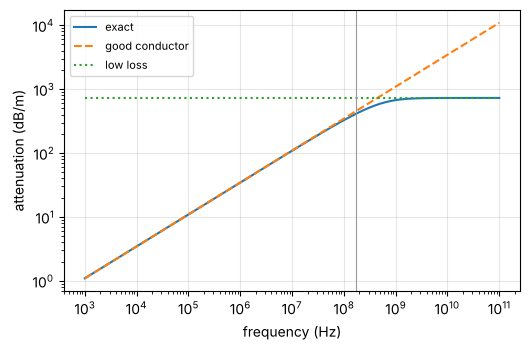

In [4]:
f = np.logspace(3, 11, 400)
a_exact = np.array([gamma_eta(ff, 4.0, 81)[0].real for ff in f])
a_gc = np.sqrt(np.pi * f * mu0 * 4.0)
a_ll = 4.0 / 2 * math.sqrt(mu0 / (81 * eps0)) * np.ones_like(f)
f10 = brentq(lambda ff: math.sqrt(math.pi * ff * mu0 * 4.0) / gamma_eta(ff, 4.0, 81)[0].real - 1.10, 1e5, 1e10)
print(f"good-conductor alpha is 10% high at {f10 / 1e6:.1f} MHz; sigma/(omega eps) = 1 at {4 / (2 * math.pi * 81 * eps0) / 1e6:.1f} MHz")
fig, ax = plt.subplots(figsize=(5.4, 3.6))
ax.loglog(f, a_exact * 8.686, label='exact'); ax.loglog(f, a_gc * 8.686, '--', label='good conductor')
ax.loglog(f, a_ll * 8.686, ':', label='low loss'); ax.axvline(f10, color='0.6', lw=0.8)
ax.set_xlabel('frequency (Hz)'); ax.set_ylabel('attenuation (dB/m)'); ax.legend(fontsize=8); ax.grid(True, which='major', alpha=0.3)
plt.tight_layout(); plt.show()

## Part 4 · The skin effect in a round wire

Inside a round wire of radius $a$ the current density obeys a Bessel equation, with solution $J(\rho) \propto J_0(k\rho)$, $k = (1 - j)/\delta$. The internal impedance per metre is $Z = \dfrac{k}{2\pi a\sigma}\dfrac{J_0(ka)}{J_1(ka)}$. Plot $\lvert J\rvert$ across a 1 mm wire at several frequencies, then $R_{ac}/R_{dc}$ against frequency with the approximations $a/2\delta$ and $a/2\delta + 1/4$.

**Predict first:** at what frequency does a 1 mm copper wire's resistance double?

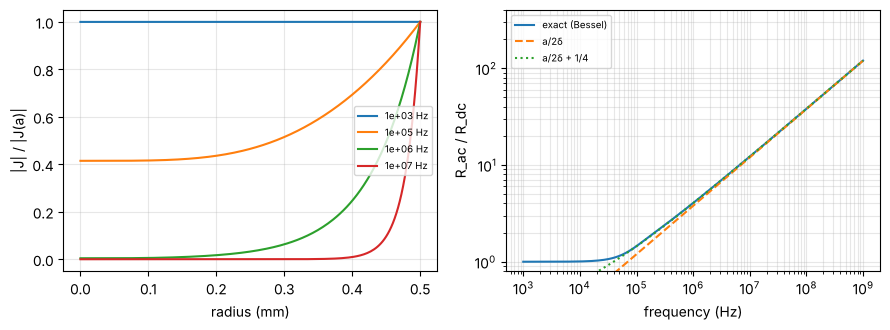

R_ac/R_dc at 1 MHz: 4.045 (a/2δ gives 3.783)
resistance doubles at 208.0 kHz, where a = 3.45 skin depths


In [5]:
a = 0.5e-3
Rdc = 1 / (sig_cu * math.pi * a**2)
k_of = lambda ff: cmath.sqrt(-1j * 2 * math.pi * ff * mu0 * sig_cu)
Z = lambda ff: k_of(ff) / (2 * math.pi * a * sig_cu) * jv(0, k_of(ff) * a) / jv(1, k_of(ff) * a)
rho = np.linspace(0, a, 200)
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4))
for ff in (1e3, 1e5, 1e6, 1e7):
    J = np.abs(jv(0, k_of(ff) * rho)); axes[0].plot(rho * 1e3, J / J[-1], label=f"{ff:.0e} Hz")
axes[0].set_xlabel('radius (mm)'); axes[0].set_ylabel('|J| / |J(a)|'); axes[0].legend(fontsize=7); axes[0].grid(alpha=0.3)
fs = np.logspace(3, 9, 300)
ratio = np.array([Z(ff).real / Rdc for ff in fs])
delta = 1 / np.sqrt(np.pi * fs * mu0 * sig_cu)
axes[1].loglog(fs, ratio, label='exact (Bessel)'); axes[1].loglog(fs, a / (2 * delta), '--', label='a/2δ')
axes[1].loglog(fs, a / (2 * delta) + 0.25, ':', label='a/2δ + 1/4')
axes[1].set_ylim(0.8, 400); axes[1].set_xlabel('frequency (Hz)'); axes[1].set_ylabel('R_ac / R_dc'); axes[1].legend(fontsize=7); axes[1].grid(True, which='both', alpha=0.3)
plt.tight_layout(); plt.show()
f2 = brentq(lambda ff: Z(ff).real / Rdc - 2, 1e3, 1e7)
print(f"R_ac/R_dc at 1 MHz: {Z(1e6).real / Rdc:.3f} (a/2δ gives {a / (2 / math.sqrt(math.pi * 1e6 * mu0 * sig_cu)):.3f})")
print(f"resistance doubles at {f2 / 1e3:.1f} kHz, where a = {a * math.sqrt(math.pi * f2 * mu0 * sig_cu):.2f} skin depths")

## What to notice

- In a lossless medium $E$ and $H$ are in phase; with loss, $H$ lags, approaching 45° in a good conductor.
- $\hat{x} - j\hat{y}$ is right-hand for travel in $+z$; swapping the sign of $j$ swaps the hand.
- Seawater needs the exact formula between about 100 MHz and 10 GHz; below, it is a good conductor, above, a lossy dielectric.
- A 1 mm wire's resistance doubles at about 200 kHz, where its radius is three and a half skin depths; above that the simple $a/2\delta$ estimate becomes accurate.